# 00 — Nauka całego projektu w 1 godzinę

Ten notatnik (notebook) jest **tylko dla Ciebie** — ma nauczyć Cię, jak działa cały program,
krok po kroku, zanim spojrzysz na prawdziwe dane. Nie potrzebujesz Google Drive, internetu
ani prawdziwego nagrania — wszystkie dane generujemy sami w pamięci, więc każda komórka (cell)
liczy się w ułamku sekundy.

**Jak to czytać:** idź od góry do dołu, odpalaj komórki po kolei (Shift+Enter). Każda sekcja
odpowiada jednemu plikowi w `rppg/` — gdy skończysz sekcję, otwórz ten plik i przeczytaj go,
kod będzie już znajomy.

To jest ta sama kolejność, w jakiej dane faktycznie płyną przez program (patrz diagram
"Data pipeline" w `README.md`):

| # | Sekcja notatnika         | Plik w projekcie       | Co robi |
|---|---------------------------|-------------------------|---------|
| 1 | Skąd bierze się sygnał    | `rppg/roi.py`           | Twarz na wideo -> obszar skóry (ROI) |
| 2 | Generujemy dane           | —                       | Sztuczny sygnał ze znanym tętnem |
| 3 | Nierówny czas             | `rppg/timeseries.py`    | Czyszczenie i resampling |
| 4 | Filtrowanie               | `rppg/groundtruth.py`   | Wycinanie pasma tętna |
| 5 | Trzy metody               | `rppg/methods.py`       | GREEN, CHROM, POS |
| 6 | Tętno w BPM               | `rppg/groundtruth.py`   | FFT i liczenie uderzeń |
| 7 | Reguły jakości            | `rppg/quality.py`       | Które okna są wiarygodne |
| 8 | Cały pipeline naraz       | `rppg/pipeline.py`      | Spaja kroki 3 i 7 |
| 9 | Efekt "wow" (EVM)         | `rppg/evm.py`           | Widoczny puls na wideo |
| 10| Co dalej                  | —                       | Realne dane, live-demo, testy |


In [1]:
import sys
import inspect
from pathlib import Path

# repo może być jeden poziom wyżej (gdy notatnik jest w notebooks/) albo tu
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(p for p in candidates if (p / "rppg").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt

from rppg.config import Config
from rppg import roi, timeseries, groundtruth, methods, quality, pipeline, evm

print("Import OK, repo root:", ROOT)


Import OK, repo root: /home/kamil/projects/Heartbeat


## 1. Skąd bierze się sygnał (`rppg/roi.py`)

Serce pompuje krew — naczynia krwionośne pod skórą na chwilę wypełniają się bardziej, skóra
odbija nieco inne światło. Zmiana jest tak mała, że ludzkie oko jej nie widzi, ale kamera ją
rejestruje jako bardzo subtelne wahania koloru (głównie w kanale zielonym). To się nazywa
**rPPG** (remote photoplethysmography — zdalny pomiar pulsu ze zmian koloru skóry).

Żeby to zmierzyć, program:
1. znajduje twarz na każdej ramce (frame) wideo (model MediaPipe Face Landmarker — 478 punktów
   na twarzy),
2. wybiera z niej trzy fragmenty skóry: czoło i dwa policzki (to jest **ROI** — region of
   interest, obszar zainteresowania),
3. liczy średni kolor (R, G, B) pikseli w każdym ROI, dla każdej ramki.

To w kodzie robi `rppg/roi.py`. Tutaj rysujemy ROI ręcznie (żeby nie czekać na ściąganie modelu
i nagrania) — prawdziwy wynik na żywej twarzy zobaczysz w `03_presentation.ipynb` albo
`scripts/live_demo.py`.


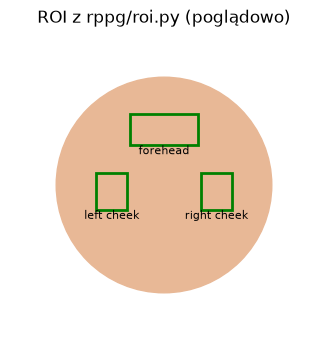

Prawdziwe nazwy ROI w kodzie: ['forehead', 'left_cheek', 'right_cheek']


In [2]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.add_patch(plt.Circle((0.5, 0.5), 0.35, color="#e8b896", zorder=1))
rois = {
    "forehead": (0.5, 0.68, 0.22, 0.10),
    "left cheek": (0.33, 0.48, 0.10, 0.12),
    "right cheek": (0.67, 0.48, 0.10, 0.12),
}
for name, (cx, cy, w, h) in rois.items():
    ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, edgecolor="green", lw=2))
    ax.text(cx, cy - h / 2 - 0.03, name, ha="center", fontsize=8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("ROI z rppg/roi.py (poglądowo)")
plt.show()

print("Prawdziwe nazwy ROI w kodzie:", roi.ROI_NAMES)


## 2. Generujemy dane (bez wideo, bez internetu)

Zamiast prawdziwego nagrania tworzymy sygnał, w którym MY z góry znamy tętno (`HR_BPM`
poniżej) — dzięki temu na końcu możemy sprawdzić, czy algorytm zgadł prawidłowo.

Naśladujemy to, co prawdziwa kamera by zarejestrowała:
- kolor "skóry" oscyluje (faluje) z częstotliwością tętna, głównie w kanale G (zielonym),
- dodajemy szum (drobne losowe zakłócenia, jak w prawdziwej kamerze),
- dodajemy wolny dryft jasności (np. zmieniające się światło w pokoju),
- znaczniki czasu (`t`) NIE są idealnie równe — tak jak w prawdziwym nagraniu: mają jitter
  (drobne wahania), jedno zduplikowane wejście i jedną przerwę (gap). Tak samo robi to
  `tests/test_pipeline_synthetic.py`, który sprawdza cały pipeline offline.


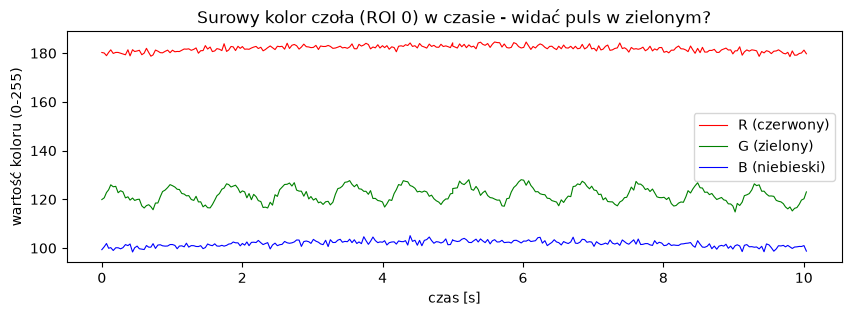

In [3]:
HR_BPM = 72.0          # "prawdziwe" tętno - porównamy z tym na końcu
FPS = 30.0
DURATION_S = 20.0
N = int(DURATION_S * FPS)
N_ROI = len(roi.ROI_NAMES)           # 3: forehead, left_cheek, right_cheek
N_LM = len(roi.MOTION_LANDMARKS)     # punkty do pomiaru ruchu głowy

rng = np.random.default_rng(0)

# --- czas: jitter + jedna duplikacja + jedna przerwa (gap), jak w prawdziwej kamerze ---
t = np.cumsum(np.r_[0, rng.uniform(1 / FPS - 0.003, 1 / FPS + 0.003, N - 1)])
t[150] = t[149]                # zduplikowany wpis w logu
t[300:] += 0.3                 # kamera "zacięła się" na 0.3 s

# --- "prawdziwy" puls (sinus + wyższa harmoniczna, jak realny sygnał PPG) ---
phase = 2 * np.pi * HR_BPM / 60 * t
pulse = np.sin(phase) + 0.3 * np.sin(2 * phase)

# --- kolor skóry: tło + puls (głównie G) + szum + wolny dryft jasności ---
base_rgb = np.array([180.0, 120.0, 100.0])              # typowy odcień skóry, sRGB 0-255
drift = 3 * np.sin(2 * np.pi * 0.05 * t)                 # wolna zmiana światła w pokoju
mean_raw = np.tile(base_rgb, (N, N_ROI, 1))
mean_raw[:, :, 1] += (4.0 * pulse)[:, None]              # puls w kanale G
mean_raw += drift[:, None, None]
mean_raw += rng.normal(0, 0.8, mean_raw.shape)           # szum kamery
mean_raw = mean_raw.astype(np.float32)

lut = roi.srgb_to_linear_lut()
mean_lin = lut[np.clip(mean_raw, 0, 255).astype(np.uint8)]

face_found = np.ones(N, bool)
clipped = np.zeros((N, N_ROI), np.float32)
motion_xy = rng.normal(0, 0.3, (N, N_LM, 2)).astype(np.float32)    # głowa prawie nieruchoma
face_width = np.full(N, 120.0, np.float32)

# --- sygnał referencyjny (pulsoksymetr) - ta sama częstotliwość, inny szum ---
ppg = pulse + rng.normal(0, 0.05, N)

raw = dict(timestamps_s=t, ppg=ppg, mean_raw=mean_raw, mean_lin=mean_lin,
           face_found=face_found, clipped_fraction=clipped,
           motion_xy=motion_xy, face_width=face_width)

channel_labels = {"r": "R (czerwony)", "g": "G (zielony)", "b": "B (niebieski)"}
plt.figure(figsize=(10, 3))
for c, colour in zip(range(3), "rgb"):
    plt.plot(t[:300], mean_raw[:300, 0, c], color=colour, lw=0.8, label=channel_labels[colour])
plt.title("Surowy kolor czoła (ROI 0) w czasie - widać puls w zielonym?")
plt.xlabel("czas [s]")
plt.ylabel("wartość koloru (0-255)")
plt.legend()
plt.show()


## 3. Nierówny czas -> jedna wspólna siatka (`rppg/timeseries.py`)

Prawdziwa kamera nie daje ramek idealnie co 1/30 s — są małe wahania (jitter), czasem
duplikat wpisu w logu, czasem zacięcie (gap). Filtr częstotliwościowy i FFT (transformata
Fouriera) wymagają jednak równych odstępów czasu. `rppg/timeseries.py` to naprawia:
- `clean_timestamps` — usuwa NaN, sortuje, scala duplikaty,
- `resample_uniform` — dopasowuje sygnał do równej siatki 30 Hz metodą splajnu (cubic
  spline — gładkiej krzywej przechodzącej przez punkty); fragmenty "zgadywane" przez
  zbyt dużą przerwę oznacza jako `valid=False`.

Poniżej prawdziwy kod tej funkcji (ten sam, który jest w pliku), a potem używamy
`pipeline.resample_subject` — też prawdziwego kodu z projektu — na naszych danych.


In [4]:
print(inspect.getsource(timeseries.clean_timestamps))


def clean_timestamps(timestamps_s, values):
    """Drop NaN rows, sort by time and merge duplicate timestamps by averaging.

    values can have any shape whose first axis matches timestamps_s, e.g. (N,), (N, 3) or (N, R, 3).
    Returns (timestamps_s_clean, values_clean, report).
    """
    timestamps_s = np.asarray(timestamps_s, dtype=float)
    values = np.asarray(values, dtype=float)
    if values.shape[0] != timestamps_s.shape[0]:
        raise ValueError(f"timestamps_s has {timestamps_s.shape[0]} samples but values has {values.shape[0]}")
    tail_shape = values.shape[1:]
    values_2d = values.reshape(len(timestamps_s), -1)        # flatten everything except time
    report = {}

    ok = np.isfinite(timestamps_s) & np.all(np.isfinite(values_2d), axis=1)
    report["nan_dropped"] = int((~ok).sum())
    timestamps_s, values_2d = timestamps_s[ok], values_2d[ok]
    if len(timestamps_s) < 2:
        raise ValueError("Fewer than 2 valid samples after dropping NaNs")

    report["ba

Raport czyszczenia czasu: {'nan_dropped': 0, 'backward_steps': 0, 'duplicates_merged': 1}
Siatka czasu: (611,) próbek. Raport resamplingu wideo: {'nan_dropped': 0, 'backward_steps': 0, 'duplicates_merged': 1, 'gaps_over_max': 1, 'largest_gap_ms': 335.3, 'invalid_fraction': 0.0164}


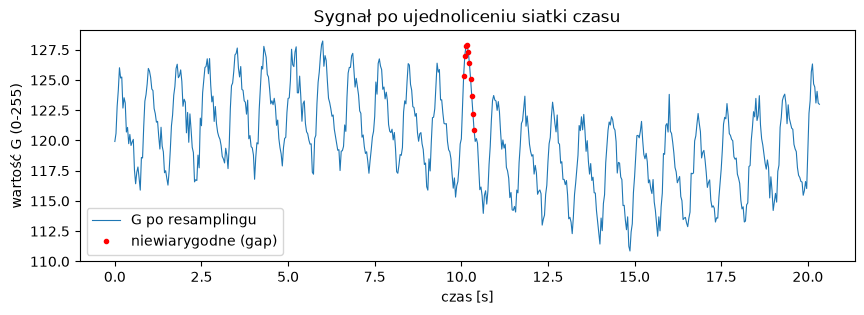

In [5]:
t_c, ppg_c, report = timeseries.clean_timestamps(raw["timestamps_s"], raw["ppg"])
print("Raport czyszczenia czasu:", report)

cfg = Config(sample_rate_hz=FPS)
res = pipeline.resample_subject(raw, cfg)
print("Siatka czasu:", res["timestamps_s"].shape, "próbek. Raport resamplingu wideo:", res["report_video"])

plt.figure(figsize=(10, 3))
plt.plot(res["timestamps_s"], res["rgb_raw"][:, 0, 1], lw=0.8, label="G po resamplingu")
plt.plot(res["timestamps_s"][~res["valid_video"]], res["rgb_raw"][~res["valid_video"], 0, 1], "r.",
         label="niewiarygodne (gap)")
plt.legend(); plt.xlabel("czas [s]"); plt.ylabel("wartość G (0-255)")
plt.title("Sygnał po ujednoliceniu siatki czasu")
plt.show()


## 4. Filtrowanie: wycinamy pasmo tętna (`rppg/groundtruth.py`)

Interesuje nas tylko zakres częstotliwości fizjologicznie możliwego tętna (domyślnie
42-180 BPM, czyli 0.7-3.0 Hz — patrz `Config.heart_rate_min_bpm` / `heart_rate_max_bpm`). `bandpass` to
filtr Butterwortha (Butterworth band-pass filter) — przepuszcza tylko to pasmo, resztę
(wolny dryft jasności, szybki szum kamery) odcina. `filtfilt` puszcza filtr w przód i w tył,
żeby nie przesunąć sygnału w czasie (zero-phase).


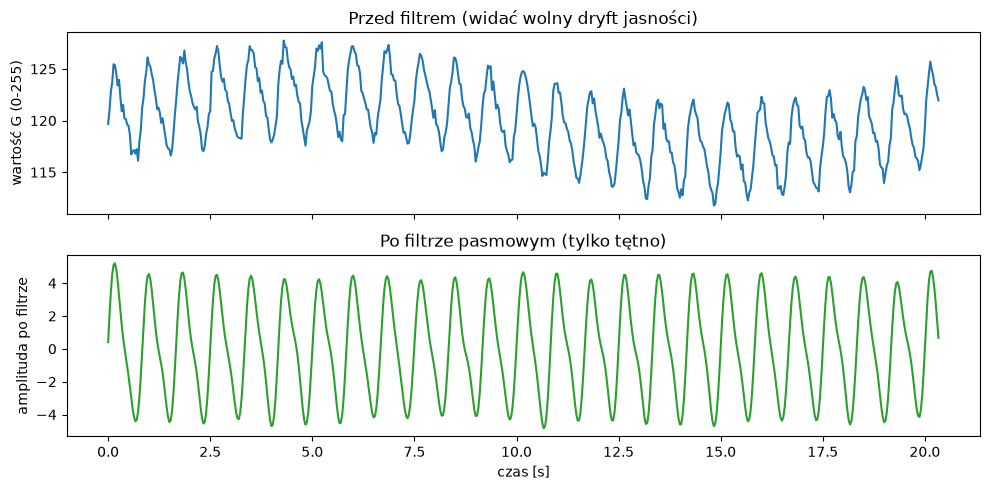

In [6]:
green_raw = res["rgb_raw"][:, :, 1].mean(axis=1)      # średnia G z 3 ROI
green_filtered = groundtruth.bandpass(green_raw, cfg.sample_rate_hz, cfg.heart_rate_min_bpm / 60, cfg.heart_rate_max_bpm / 60)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(res["timestamps_s"], green_raw)
axes[0].set_title("Przed filtrem (widać wolny dryft jasności)")
axes[0].set_ylabel("wartość G (0-255)")
axes[1].plot(res["timestamps_s"], green_filtered, color="tab:green")
axes[1].set_title("Po filtrze pasmowym (tylko tętno)")
axes[1].set_xlabel("czas [s]")
axes[1].set_ylabel("amplituda po filtrze")
plt.tight_layout(); plt.show()


## 5. Trzy metody rPPG (`rppg/methods.py`)

Z trzech kolorów (R, G, B) w czasie każda metoda wylicza JEDEN sygnał pulsu, inaczej
radząc sobie z zakłóceniami od ruchu/światła:
- **GREEN** — po prostu kanał zielony (po odtrendowaniu, czyli usunięciu wolnego trendu).
  Proste, ale wrażliwe na ruch/światło.
- **CHROM** — kombinacja R, G, B zaprojektowana tak, by odjąć wspólny "błysk"
  (artefakt jasności/odbicia światła).
- **POS** — rzutuje sygnał na płaszczyznę prostopadłą do kierunku "jasność/odcień skóry",
  w krótkich, nakładających się oknach czasowych.


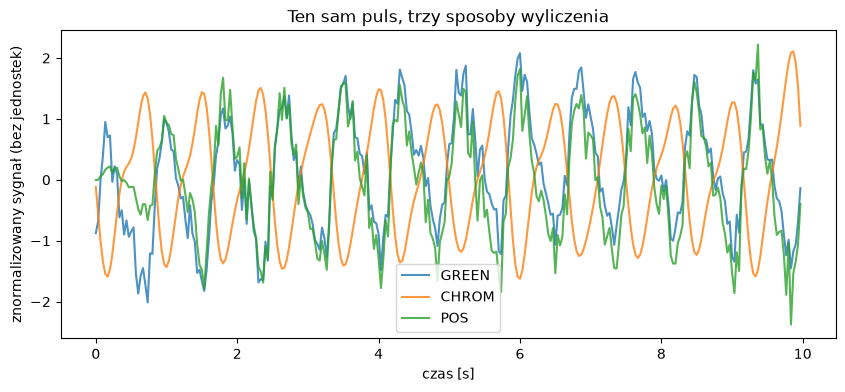

In [7]:
rgb_forehead = res["rgb_raw"][:, 0, :]    # (T, 3) - kanały R,G,B samego czoła

sig_green = methods.green(rgb_forehead)
sig_chrom = methods.chrom(rgb_forehead, cfg.sample_rate_hz, cfg.heart_rate_min_bpm / 60, cfg.heart_rate_max_bpm / 60)
sig_pos = methods.pos(rgb_forehead, cfg.sample_rate_hz)

def norm(x):
    return (x - x.mean()) / x.std()

plt.figure(figsize=(10, 4))
for sig, label in [(sig_green, "GREEN"), (sig_chrom, "CHROM"), (sig_pos, "POS")]:
    plt.plot(res["timestamps_s"][:300], norm(sig)[:300], label=label, alpha=0.8)
plt.legend(); plt.xlabel("czas [s]"); plt.ylabel("znormalizowany sygnał (bez jednostek)")
plt.title("Ten sam puls, trzy sposoby wyliczenia")
plt.show()


## 6. Tętno w BPM (`rppg/groundtruth.py`)

Sygnał pulsu -> jedna liczba: tętno w **BPM** (beats per minute — uderzenia na minutę).
Dwa niezależne sposoby:
- `hr_spectral` — FFT (transformata Fouriera: "z jakich częstotliwości składa się sygnał"),
  bierzemy najsilniejszy pik w paśmie tętna,
- `hr_peaks` — liczymy odstępy czasu między kolejnymi uderzeniami (szczytami sygnału,
  ang. peaks) i bierzemy medianę.

Jeśli te dwie metody się nie zgadzają na sygnale referencyjnym, to znak, że samo to okno
referencji jest niewiarygodne (patrz sekcja 7) — ważna decyzja projektowa: nie ufamy
referencji bez sprawdzenia.


In [8]:
for name, sig in [("GREEN", sig_green), ("CHROM", sig_chrom), ("POS", sig_pos)]:
    bpm = groundtruth.hr_spectral(sig, cfg.sample_rate_hz, cfg.heart_rate_min_bpm, cfg.heart_rate_max_bpm)
    print(f"{name:6s}: {bpm:6.2f} BPM   (prawdziwe tętno: {HR_BPM:.0f} BPM)")

ref_fft, ref_peaks = groundtruth.reference_hr(res["ppg"], cfg.sample_rate_hz, cfg.heart_rate_min_bpm, cfg.heart_rate_max_bpm)
print(f"Referencja (PPG): FFT={ref_fft:.2f} BPM, licznik uderzeń={ref_peaks:.2f} BPM")


GREEN :  71.96 BPM   (prawdziwe tętno: 72 BPM)
CHROM :  71.96 BPM   (prawdziwe tętno: 72 BPM)
POS   :  71.96 BPM   (prawdziwe tętno: 72 BPM)
Referencja (PPG): FFT=71.96 BPM, licznik uderzeń=72.00 BPM


## 7. Reguły jakości okien (`rppg/quality.py`)

Zanim ocenia się algorytm, dzieli się nagranie na 8-sekundowe okna (windows) i dla każdego
sprawdza się **TYLKO jakość wejścia** (braki w danych, zgubiona twarz, prześwietlone
piksele, niewiarygodna referencja) — NIGDY jakość wyniku algorytmu. (Odrzucanie okien
dlatego, że akurat na nich algorytm wypadł słabo, byłoby naginaniem wyników pod
oczekiwany rezultat — po angielsku "cherry-picking".)

Zobaczmy to na dwóch przykładach: nasze dobre dane z sekcji 2, oraz te same dane z
2-sekundową "zgubioną twarzą" w środku nagrania.


In [9]:
windows_good = quality.build_windows("demo", raw, res, cfg)
n_ok = sum(w["accepted"] for w in windows_good)
print(f"Dobre dane: {n_ok}/{len(windows_good)} okien zaakceptowanych")

raw_bad = dict(raw)
raw_bad["face_found"] = raw["face_found"].copy()
raw_bad["face_found"][200:260] = False     # ~2 s zgubionej twarzy

windows_bad = quality.build_windows("demo", raw_bad, res, cfg)
n_ok_bad = sum(w["accepted"] for w in windows_bad)
rejected = next(w for w in windows_bad if not w["accepted"])
print(f"Ze zgubioną twarzą: {n_ok_bad}/{len(windows_bad)} zaakceptowanych")
print("Przykład odrzuconego okna:", rejected)


Dobre dane: 13/13 okien zaakceptowanych
Ze zgubioną twarzą: 4/13 zaakceptowanych
Przykład odrzuconego okna: {'subject': 'demo', 'window_index': 0, 'window_start_s': 0.0, 'window_end_s': 8.0, 'reference_heart_rate_bpm': 72.07, 'reference_heart_rate_peaks_bpm': 72.0, 'gap_fraction': 0.0, 'face_missing_fraction': 0.1632, 'clipped_fraction': 0.0, 'head_motion': 0.00036, 'accepted': False, 'reject_reasons': 'face_missing'}


## 8. Cały pipeline naraz (`rppg/pipeline.py`)

`pipeline.py` to "dyrygent" (orchestrator) — w prawdziwym projekcie łączy wczytanie wideo
(`roi.process_video`, wymaga FFmpeg i modelu MediaPipe pobranego z internetu) z krokami,
które właśnie przeszliśmy ręcznie: `resample_subject` + `quality.build_windows`
(zapakowane razem w `build_window_table`, który dodatkowo zapisuje wynik do pliku
`windows.csv`). Dokładnie te dwie funkcje użyłaś/-eś powyżej samodzielnie — `pipeline.py`
tylko spina to w jedną całość dla wielu uczestników (subjects) i zarządza zapisem na dysk
(cache), żeby nie przerabiać 32 GB wideo od zera za każdym razem.

Dlatego tutaj nie odpalamy `pipeline.build_cache` (potrzebuje FFmpeg + modelu + prawdziwego
wideo) — to robi `notebooks/02_build_cache.ipynb` w Colabie. Zobacz za to prawdziwy kod,
który to łączy:


In [10]:
print(inspect.getsource(pipeline.build_window_table))


def build_window_table(cfg: Config, subjects=None):
    """Windows with reference HR + quality flags for every cached subject -> windows.csv."""
    subjects = subjects or sorted(
        (f[:-4] for f in os.listdir(cfg.cache_dir) if f.startswith("subject") and f.endswith(".npz")),
        key=lambda s: int(s[len("subject"):]))
    rows = []
    for subject in subjects:
        try:
            raw = load_subject(cfg, subject)
            res = resample_subject(raw, cfg)
            rows.extend(build_windows(subject, raw, res, cfg))
        except Exception as exc:            # one broken subject must not stop the whole table
            print(f"{subject}: skipped ({type(exc).__name__}: {exc})")
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(cfg.cache_dir, "windows.csv"), index=False)
    return df



## 9. Efekt "wow": widoczny puls (`rppg/evm.py`)

**Eulerian Video Magnification (EVM)** wzmacnia na wideo tylko zmiany w paśmie tętna —
subtelne, niewidoczne okiem pulsowanie koloru staje się widoczne. Robimy to na malutkim,
sztucznym klipie (nie trzeba prawdziwego wideo) - zobacz, jak bardzo rośnie amplituda
(wychylenie) sygnału w jednym pikselu po wzmocnieniu.


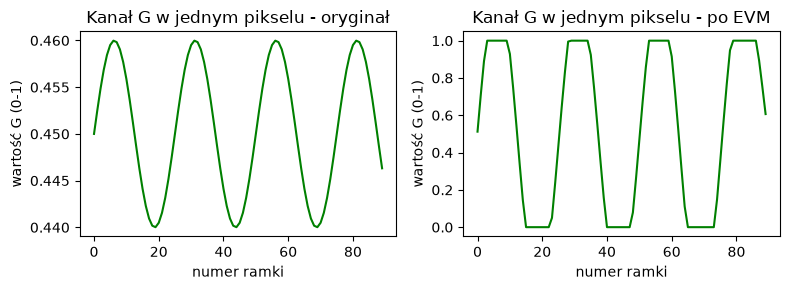

Odchylenie standardowe G przed EVM: 0.006934928
Odchylenie standardowe G po EVM:    0.4239155


In [11]:
T, H, W = 90, 48, 48
clip_pulse = np.sin(2 * np.pi * HR_BPM / 60 * np.arange(T) / FPS)
frames = np.tile(np.array([0.70, 0.45, 0.40], np.float32), (T, H, W, 1))
frames[:, :, :, 1] += (0.01 * clip_pulse)[:, None, None]     # ledwo widoczna zmiana G
frames = np.clip(frames, 0, 1).astype(np.float32)

magnified = evm.magnify_color(frames, FPS, cfg.heart_rate_min_bpm / 60, cfg.heart_rate_max_bpm / 60, magnification_gain=80.0)

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=False)
axes[0].plot(frames[:, H // 2, W // 2, 1], color="green")
axes[0].set_title("Kanał G w jednym pikselu - oryginał")
axes[0].set_xlabel("numer ramki"); axes[0].set_ylabel("wartość G (0-1)")
axes[1].plot(magnified[:, H // 2, W // 2, 1], color="green")
axes[1].set_title("Kanał G w jednym pikselu - po EVM")
axes[1].set_xlabel("numer ramki"); axes[1].set_ylabel("wartość G (0-1)")
plt.tight_layout(); plt.show()

print("Odchylenie standardowe G przed EVM:", frames[:, H // 2, W // 2, 1].std())
print("Odchylenie standardowe G po EVM:   ", magnified[:, H // 2, W // 2, 1].std())


## 10. Co dalej

Przeszliśmy cały łańcuch: wideo -> ROI -> czyszczenie czasu -> filtr -> metoda
(GREEN/CHROM/POS) -> BPM -> reguły jakości -> (efekt "wow") EVM. Dokładnie w tej kolejności
opisuje to diagram "Data pipeline" w `README.md` i realizuje `notebooks/03_presentation.ipynb`
— ale na prawdziwym nagraniu z UBFC-rPPG.

Co zrobić teraz:
- **`pytest -q`** — odpal testy; każdy sprawdza jedną z funkcji, które właśnie przeszłaś/-eś.
- **`notebooks/03_presentation.ipynb`** (w Colab) — to samo, na prawdziwej twarzy z UBFC-rPPG.
- **`python scripts/live_demo.py`** — zobacz WŁASNY puls na żywo z kamerki, z sześcioma
  oknami pokazującymi każdy etap po kolei.
- **`notebooks/02_build_cache.ipynb`** — gdy zechcesz przetworzyć cały zbiór danych
  UBFC-rPPG (potrzebny plik `ubfc_rppg.zip` na Google Drive).
